Processing: C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\1.5_01.csv
--- Fit Results ---
Initial Amplitude (A): 8.7722 V
Decay Factor (T_2):     31.4720 ms
Baseline Offset (C):    -0.0599 V



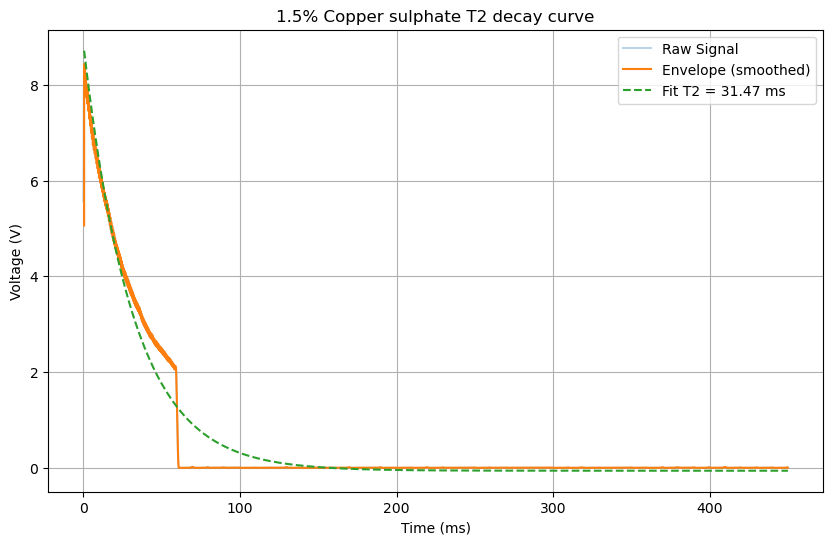

Processing: C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\3.1_1.csv
--- Fit Results ---
Initial Amplitude (A): 5.9035 V
Decay Factor (T_2):     18.4727 ms
Baseline Offset (C):    0.0220 V



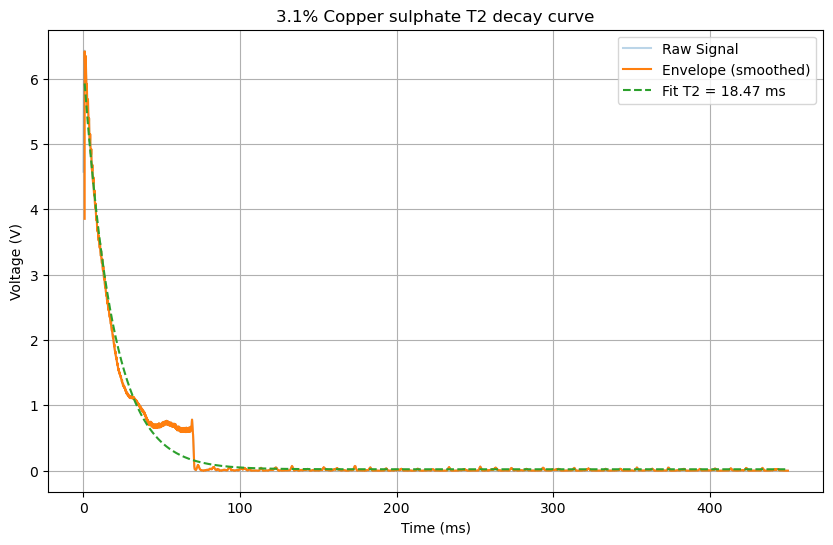

Processing: C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\12.5_1.csv
--- Fit Results ---
Initial Amplitude (A): 5.5771 V
Decay Factor (T_2):     3.0242 ms
Baseline Offset (C):    0.0854 V



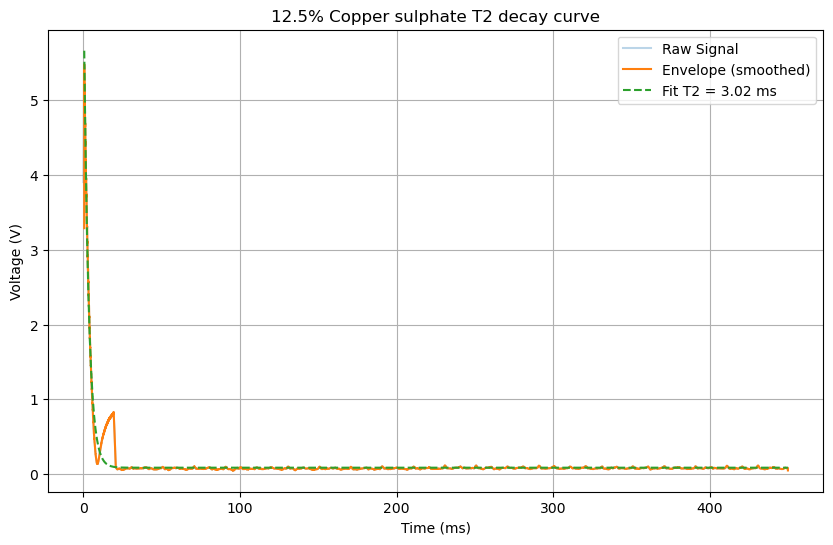

Processing: C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\25_01.csv
--- Fit Results ---
Initial Amplitude (A): 4.9216 V
Decay Factor (T_2):     5.1144 ms
Baseline Offset (C):    0.0642 V



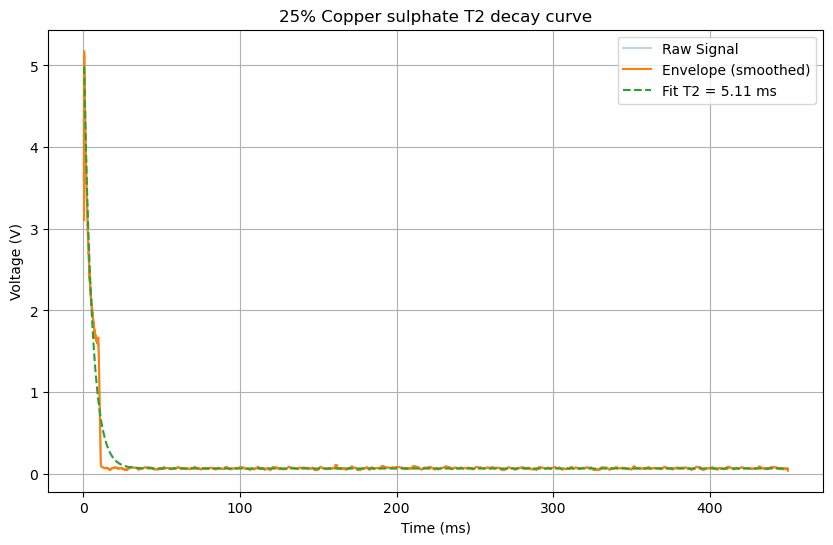

Processing: C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\50_01.csv
--- Fit Results ---
Initial Amplitude (A): 4.3450 V
Decay Factor (T_2):     2.5173 ms
Baseline Offset (C):    0.0550 V



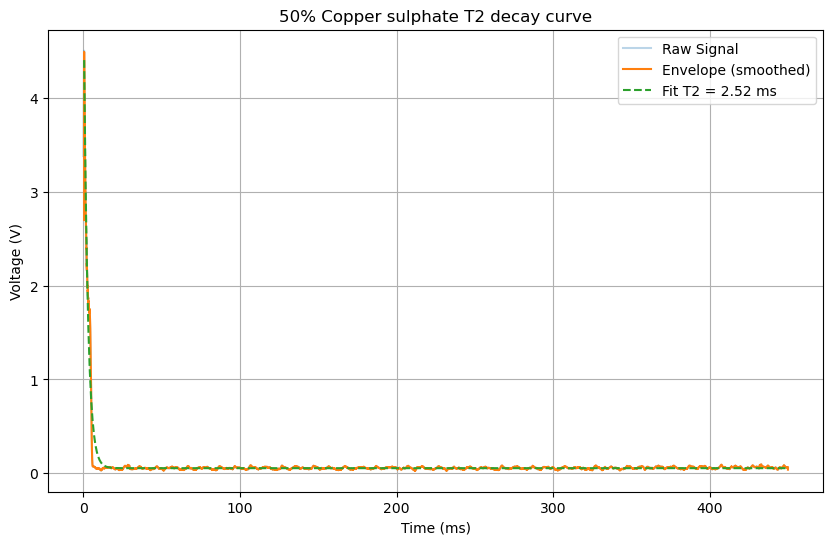

Processing: C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\75_01.csv
--- Fit Results ---
Initial Amplitude (A): 4.2765 V
Decay Factor (T_2):     2.9117 ms
Baseline Offset (C):    0.0714 V



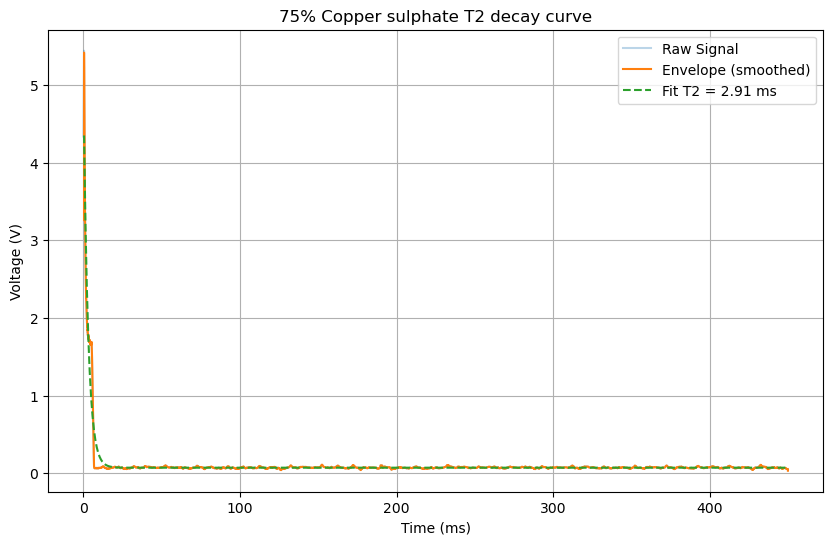

Processing: C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\90_01.csv
--- Fit Results ---
Initial Amplitude (A): 2.2206 V
Decay Factor (T_2):     2.7642 ms
Baseline Offset (C):    0.0560 V



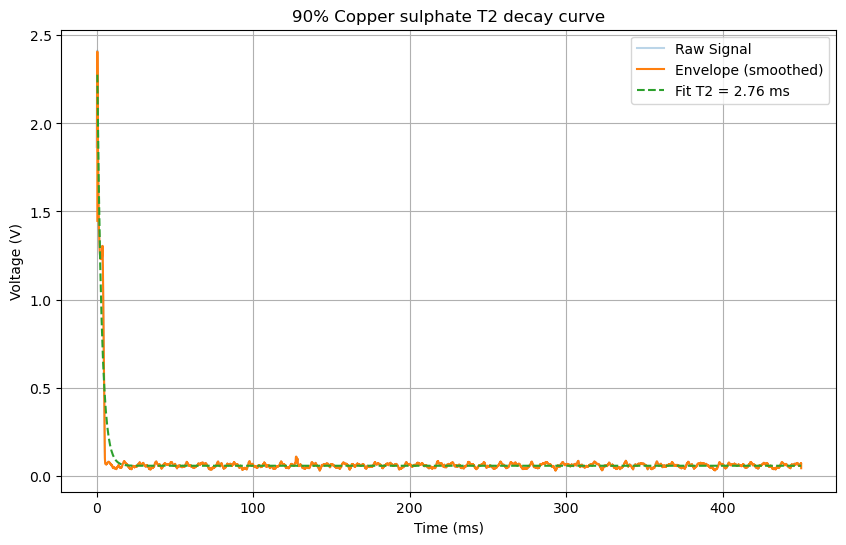

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def process_t2_cpmg(filepath, graph_title, auto_trim=True):
    print(f"\nProcessing: {filepath}")

    # 1. Load and clean data
    data = pd.read_csv(filepath, encoding='windows-1252', skiprows=1)

    # Keep only first two columns (time, voltage)
    data = data.iloc[:, :2]
    data.columns = ['time', 'voltage']

    data['time'] = pd.to_numeric(data['time'], errors='coerce')
    data['voltage'] = pd.to_numeric(data['voltage'], errors='coerce')
    data = data.dropna()

    # Convert to numpy
    t = data['time'].values
    v = data['voltage'].values

    # 2. Find start of decay (global max = first echo / pulse)
    max_idx = np.argmax(v)
    t_decay = t[max_idx:]
    v_decay = v[max_idx:]

    if len(v_decay) < 20:
        print("Error: Not enough decay data.")
        return

    # 3. Envelope extraction (absolute value)
    v_env = np.abs(v_decay)

    # 4. Smooth envelope (reduces oscilloscope noise)
    window = max(5, int(len(v_env) * 0.01))  # adaptive smoothing
    kernel = np.ones(window) / window
    v_smooth = np.convolve(v_env, kernel, mode='same')

    # 5. Zero time for numerical stability
    t_zero = t_decay - t_decay[0]

    # 6. Estimate noise floor from last 20% of data
    tail_start = int(len(v_smooth) * 0.8)
    noise_std = np.std(v_smooth[tail_start:])
    noise_threshold = 3 * noise_std

    # 7. Auto-trim when signal reaches noise floor (KEY for fast T2)
    if auto_trim:
        valid_indices = np.where(v_smooth > noise_threshold)[0]
        if len(valid_indices) > 10:
            last_signal_index = valid_indices[-1]
            t_zero = t_zero[:last_signal_index]
            v_smooth = v_smooth[:last_signal_index]

    if len(v_smooth) < 10:
        print("Error: Signal too short after trimming.")
        return

    # 8. Log-linear fit (more stable than curve_fit for fast decays)
    positive_mask = v_smooth > 0
    t_fit = t_zero[positive_mask]
    v_fit = v_smooth[positive_mask]

    log_v = np.log(v_fit)

    # Linear regression: ln(V) = ln(A) - t/T2
    coeffs = np.polyfit(t_fit, log_v, 1)
    slope, intercept = coeffs

    T2 = -1 / slope
    A = np.exp(intercept)

    print(f"--- Fit Results (Log-Linear Method) ---")
    print(f"Initial Amplitude (A): {A:.4f} V")
    print(f"Decay Factor (T₂):     {T2:.4f} ms")

    # 9. Generate fitted curve
    t_plot = np.linspace(0, t_zero.max(), 500)
    v_model = A * np.exp(-t_plot / T2)

    # Convert back to absolute time for plotting
    t_plot_abs = t_plot + t_decay[0]

    # 10. Plot (lab-report quality)
    plt.figure(figsize=(10, 6))
    plt.plot(t, v, alpha=0.3, label='Raw Signal')
    plt.plot(t_decay, v_smooth, linewidth=2, label='Envelope (smoothed)')
    plt.plot(t_plot_abs, v_model, '--', linewidth=2,
             label=f'Exponential Fit: T₂ = {T2:.2f} ms')

    plt.title(graph_title, fontsize=14)
    plt.xlabel('Time (ms)', fontsize=12)
    plt.ylabel('Voltage (V)', fontsize=12)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    return T2

my_title = "1.5% Copper sulphate T2 decay curve"
file_path = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\1.5_01.csv"
process_t2_fast_decay(file_path, my_title)

my_title = "3.1% Copper sulphate T2 decay curve"
file_path = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\3.1_1.csv"
process_t2_fast_decay(file_path, my_title)

my_title = "12.5% Copper sulphate T2 decay curve"
file_path = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\12.5_1.csv"
process_t2_fast_decay(file_path, my_title)

my_title = "25% Copper sulphate T2 decay curve"
file_path = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\25_01.csv"
process_t2_fast_decay(file_path, my_title)

my_title = "50% Copper sulphate T2 decay curve"
file_path = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\50_01.csv"
process_t2_fast_decay(file_path, my_title)

my_title = "75% Copper sulphate T2 decay curve"
file_path = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\75_01.csv"
process_t2_fast_decay(file_path, my_title)

my_title = "90% Copper sulphate T2 decay curve"
file_path = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\90_01.csv"
process_t2_fast_decay(file_path, my_title)



Processing: C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\1.5_01.csv


ValueError: x and y must have same first dimension, but have shapes (11784,) and (11782,)

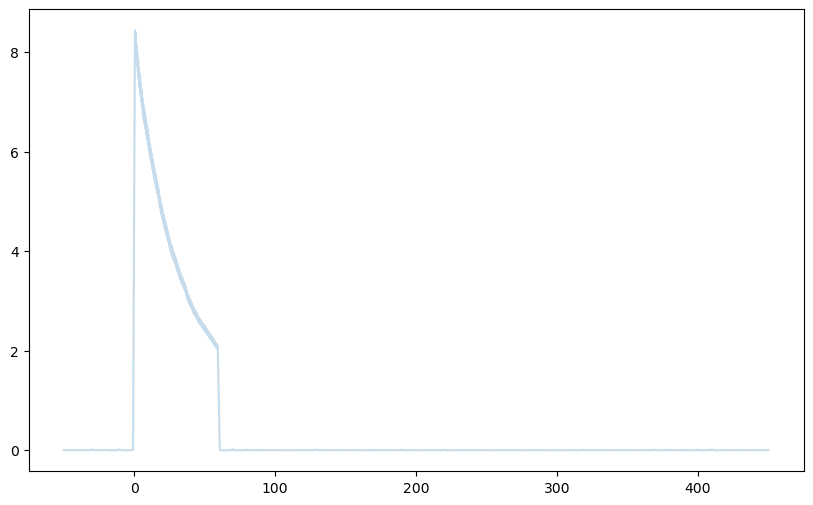

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def process_t2_cpmg_dynamic(filepath, graph_title,
                            signal_threshold=0.3,
                            auto_trim=True):

    print(f"\nProcessing: {filepath}")

    # ---------------------------------
    # 1. Load and clean data
    # ---------------------------------
    data = pd.read_csv(filepath, encoding='windows-1252', skiprows=1)
    data = data.iloc[:, :2]
    data.columns = ['time', 'voltage']

    data['time'] = pd.to_numeric(data['time'], errors='coerce')
    data['voltage'] = pd.to_numeric(data['voltage'], errors='coerce')
    data = data.dropna()

    t = data['time'].values
    v = data['voltage'].values

    if len(t) < 50:
        print("File too short.")
        return None

    # ---------------------------------
    # 2. Find start of decay (main peak)
    # ---------------------------------
    max_idx = np.argmax(v)
    t_decay = t[max_idx:].copy()
    v_decay = v[max_idx:].copy()

    if len(t_decay) < 20:
        print("Not enough decay data.")
        return None

    # ---------------------------------
    # 3. Envelope extraction (robust for echoes)
    # ---------------------------------
    v_env = np.abs(v_decay)

    # Adaptive smoothing to suppress noise
    window = max(5, int(len(v_env) * 0.005))
    kernel = np.ones(window) / window
    v_smooth = np.convolve(v_env, kernel, mode='same')

    # ---------------------------------
    # 4. DYNAMIC TIME WINDOW (0.3 V rule)
    # ---------------------------------
    above_threshold = np.where(v_smooth >= signal_threshold)[0]

    if len(above_threshold) > 20:
        last_signal_idx = above_threshold[-1]
        t_decay = t_decay[:last_signal_idx]
        v_smooth = v_smooth[:last_signal_idx]
    else:
        # Fallback if signal is very weak (high concentration samples)
        print("Warning: Signal barely above threshold, using noise-based trim.")
        tail_start = int(len(v_smooth) * 0.7)
        noise_std = np.std(v_smooth[tail_start:])
        noise_threshold = 3 * noise_std

        valid = np.where(v_smooth > noise_threshold)[0]
        if len(valid) > 20:
            last_signal_idx = valid[-1]
            t_decay = t_decay[:last_signal_idx]
            v_smooth = v_smooth[:last_signal_idx]

    if len(v_smooth) < 10:
        print("Signal too weak after dynamic trimming.")
        return None

       # ---------------------------------
    # 5. Zero time
    # ---------------------------------
    t_zero = t_decay - t_decay[0]
    
    # ---------------------------------
    # 6. Remove non-monotonic regions (kills bad second echo)
    # ---------------------------------
    dv = np.diff(v_smooth)
    
    # We expect decay → derivative should be mostly negative
    monotonic_region = np.where(dv < 0)[0]
    
    if len(monotonic_region) > 20:
        last_good = monotonic_region[-1]
        t_zero = t_zero[:last_good]
        v_smooth = v_smooth[:last_good]
    
    # ---------------------------------
    # 7. Log-linear fit
    # ---------------------------------
    positive_mask = v_smooth > 0
    t_fit = t_zero[positive_mask]
    v_fit = v_smooth[positive_mask]
    
    if len(v_fit) < 10:
        print("Not enough clean points for fitting.")
        return None
    
    log_v = np.log(v_fit)
    slope, intercept = np.polyfit(t_fit, log_v, 1)
    
    T2 = -1 / slope
    A = np.exp(intercept)
    # ---------------------------------
    # 8. Plot (clean + professional)
    # ---------------------------------
    plt.figure(figsize=(10, 6))
    plt.plot(t, v, alpha=0.25, label="Raw Signal")
    plt.plot(t_decay, v_smooth, linewidth=2, label="Envelope (smoothed)")
    plt.plot(t_model_abs, v_model, '--', linewidth=2,
             label=f"Exponential Fit (T₂ = {T2:.2f} ms)")
    plt.axhline(signal_threshold, linestyle=':', linewidth=1,
                label=f"Threshold = {signal_threshold} V")

    plt.title(graph_title)
    plt.xlabel("Time (ms)")
    plt.ylabel("Voltage (V)")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    return T2


# ==========================================================
# RUN ALL YOUR FILES (Dynamic per dataset)
# ==========================================================
files = [
    (r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\1.5_01.csv",
     "1.5% Copper sulphate T2 decay curve"),

    (r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\3.1_1.csv",
     "3.1% Copper sulphate T2 decay curve"),

    (r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\12.5_1.csv",
     "12.5% Copper sulphate T2 decay curve"),

    (r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\25_01.csv",
     "25% Copper sulphate T2 decay curve"),

    (r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\50_01.csv",
     "50% Copper sulphate T2 decay curve"),

    (r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\75_01.csv",
     "75% Copper sulphate T2 decay curve"),

    (r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\90_01.csv",
     "90% Copper sulphate T2 decay curve"),
]

results = []

for path, title in files:
    T2 = process_t2_cpmg_dynamic(path, title, signal_threshold=0.3)
    if T2 is not None:
        results.append((title, T2))

print("\nSummary of T₂ values:")
for name, val in results:
    print(f"{name}: {val:.3f} ms")


Processing: C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\1.5_01.csv


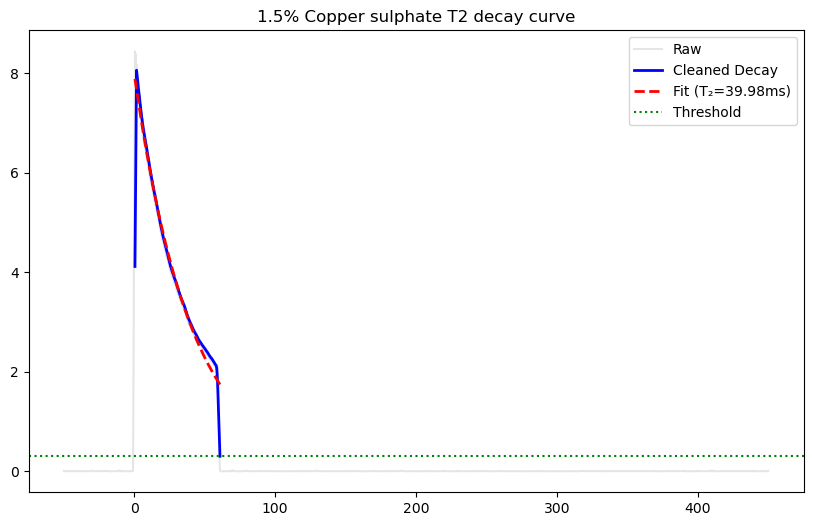


Processing: C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\3.1_1.csv


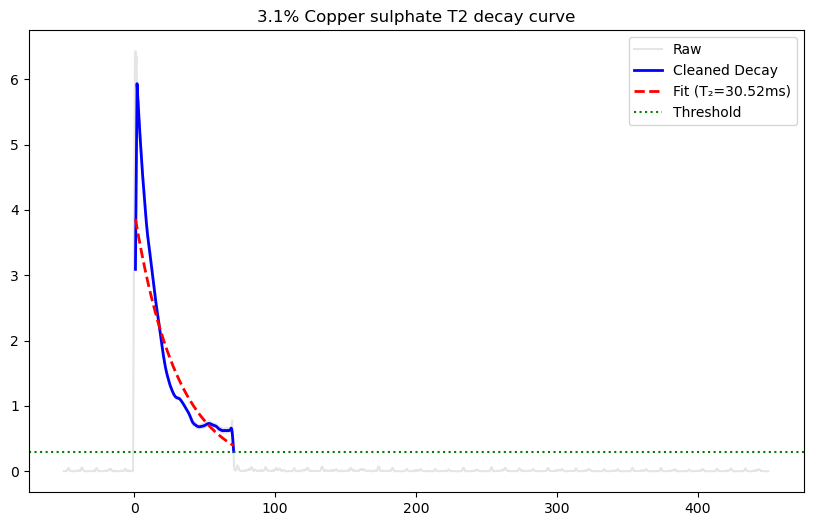


Processing: C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\12.5_1.csv


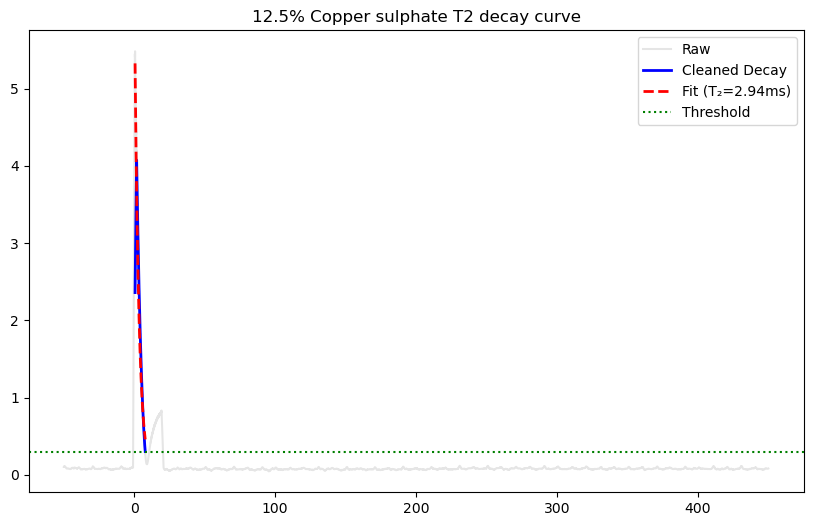


Processing: C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\25_01.csv


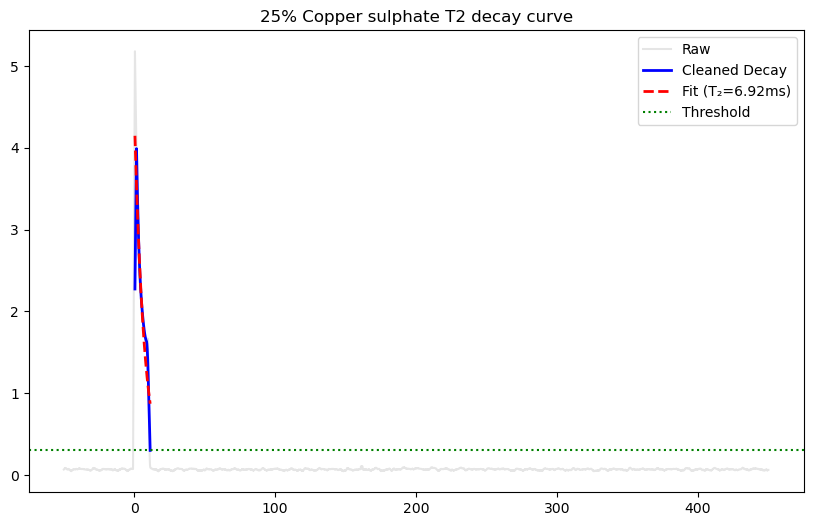


Processing: C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\50_01.csv


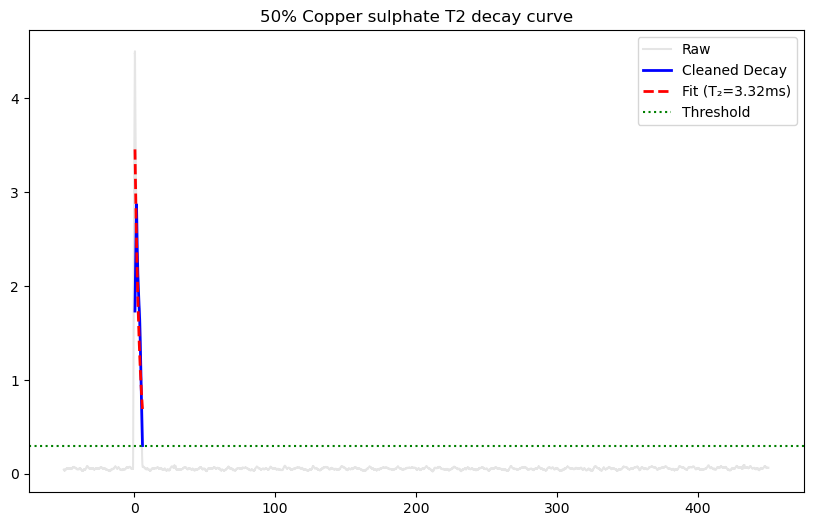


Processing: C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\75_01.csv


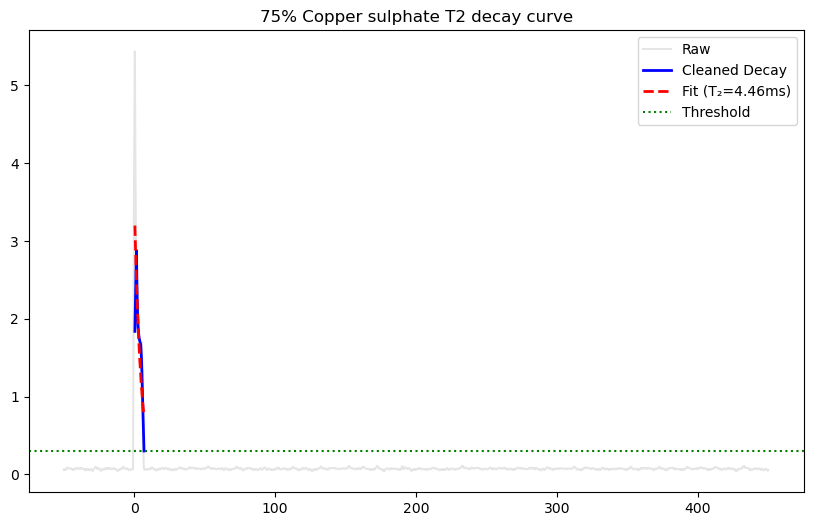


Processing: C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\90_01.csv


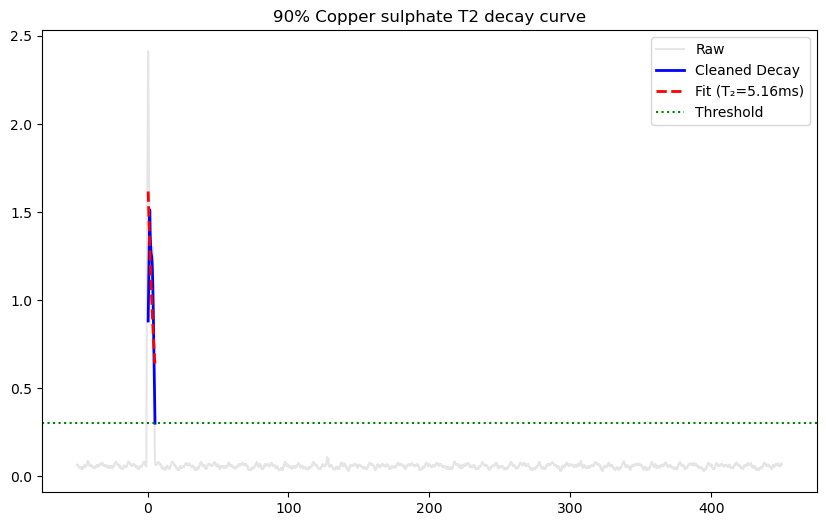


Summary of T₂ values:
1.5% Copper sulphate T2 decay curve: 39.982 ms
3.1% Copper sulphate T2 decay curve: 30.520 ms
12.5% Copper sulphate T2 decay curve: 2.942 ms
25% Copper sulphate T2 decay curve: 6.921 ms
50% Copper sulphate T2 decay curve: 3.324 ms
75% Copper sulphate T2 decay curve: 4.461 ms
90% Copper sulphate T2 decay curve: 5.163 ms


In [28]:
def process_t2_cpmg_dynamic(filepath, graph_title, signal_threshold=0.3):
    print(f"\nProcessing: {filepath}")

    # 1. Load and Clean
    data = pd.read_csv(filepath, encoding='windows-1252', skiprows=1).iloc[:, :2]
    data.columns = ['time', 'voltage']
    data = data.apply(pd.to_numeric, errors='coerce').dropna()
    t, v = data['time'].values, data['voltage'].values

    # 2. Find Start of Decay
    max_idx = np.argmax(v)
    t_decay = t[max_idx:].copy()
    v_raw_decay = v[max_idx:].copy()

    # 3. Envelope & Smoothing (Defined early to avoid UnboundLocalError)
    window = max(5, int(len(v_raw_decay) * 0.005))
    v_smooth = np.convolve(np.abs(v_raw_decay), np.ones(window)/window, mode='same')

  # ... [Steps 1-3 remain the same] ...

    # 4. Trim to First Decay
    dv = np.diff(v_smooth)
    stop_idx = len(v_smooth)
    
    above_thresh = np.where(v_smooth < signal_threshold)[0]
    if len(above_thresh) > 0:
        stop_idx = min(stop_idx, above_thresh[0])
        
    # FIX: Added a small offset (e.g., [5:]) so it doesn't 
    # trigger a "rise" on the very first noisy peak
    rising_indices = np.where(dv[5:] > 0.02)[0] 
    if len(rising_indices) > 0:
        # Re-adjust index because we sliced dv
        actual_rise_idx = rising_indices[0] + 5
        if actual_rise_idx < stop_idx:
            stop_idx = actual_rise_idx

    # --- SAFETY CHECK ---
    if stop_idx < 5:
        print(f"Skipping {graph_title}: No valid decay found above threshold.")
        return None

    t_final = t_decay[:stop_idx]
    v_final = v_smooth[:stop_idx]
    
    # Now this is safe from IndexError
    t_zero = t_final - t_final[0]
    # 5. Fit
    mask = v_final > 0
    if len(v_final[mask]) < 5: return None
    
    slope, intercept = np.polyfit(t_zero[mask], np.log(v_final[mask]), 1)
    T2, A = -1/slope, np.exp(intercept)
    v_model = A * np.exp(-t_zero / T2)

    # 6. Plot
    plt.figure(figsize=(10, 6))
    plt.plot(t, v, alpha=0.2, label="Raw", color='gray')
    plt.plot(t_final, v_final, lw=2, label="Cleaned Decay", color='blue')
    plt.plot(t_final, v_model, '--', lw=2, color='red', label=f"Fit (T₂={T2:.2f}ms)")
    plt.axhline(signal_threshold, ls=':', color='green', label='Threshold')
    plt.title(graph_title)
    plt.legend()
    plt.show()

    return T2

# ==========================================================
# RUN ALL YOUR FILES (Dynamic per dataset)
# ==========================================================
files = [
    (r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\1.5_01.csv",
     "1.5% Copper sulphate T2 decay curve"),

    (r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\3.1_1.csv",
     "3.1% Copper sulphate T2 decay curve"),

    (r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\12.5_1.csv",
     "12.5% Copper sulphate T2 decay curve"),

    (r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\25_01.csv",
     "25% Copper sulphate T2 decay curve"),

    (r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\50_01.csv",
     "50% Copper sulphate T2 decay curve"),

    (r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\75_01.csv",
     "75% Copper sulphate T2 decay curve"),

    (r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Non temperature\T2\Copper sulphate T2\90_01.csv",
     "90% Copper sulphate T2 decay curve"),
]

results = []

for path, title in files:
    T2 = process_t2_cpmg_dynamic(path, title, signal_threshold=0.3)
    if T2 is not None:
        results.append((title, T2))

print("\nSummary of T₂ values:")
for name, val in results:
     print(f"{name}: {val:.3f} ms")